# Counting ships in the port of Constanța with Sentinel-1
*Luca Tarchila, Paulian Oprescu, Phuong Nguyen, Ravian Hendriks · Geoscripting, WUR, 2026*

Constanța is the largest port in the Black Sea. After Russia invaded Ukraine in 2022, it became an important logistic hub for the grain of Ukraine. Did that change how many vessels there were in the port?

We count vessels in the port and the offshore anchorage on Sentinel-1 radar images from 2019 to 2025, uusing Google Earth Engine. Radar can see strough clouds and works at night. Ships show up as bright spots on dark water.

**Questions**
1. How many vessels can we detect with a simple brightness threshold?
2. Did the number of vessels change after the war started?

**Table of contents**
* **Settings:** all variables that are used in one cell
* **Step 1-5:** water mask, images, detection, time series, before vs after
* **What we tried:** methods that didn't work and why
* Results are saved in `data/`, so rerunning the notebook skips the slow calculation part.

## Pixi install instructions

## Before you start: Google Earth Engine access
https://geoscripting-wur.github.io/Python-GEE/
This project uses Google Earth Engine. To work with Google Earth Engine (GEE), you will need a Google account for authorization. The authentication process can be initiated by calling the Authenticate function from the ee module. Follow these steps:

1. After running the Authenticate function below, a URL will be printed in the output.
2. Click on the URL, which will redirect you to a Google account login page.
3. Log in to your Google account to create an authorization token.
4. When prompted with a warning stating that Google has not verified the app, click “Continue”. This warning is shown because the code we are about to run is not verified by Google, ensuring your account’s security.
5. On the authorization page, select all the checkboxes. This grants permission to access GEE data and manage data and permissions in the cloud storage where the analysis will be performed.
6. Finally, you will see an authorization code. Copy the code and paste it into the text box that appears after running the Authenticate function. Press Enter to complete the authentication process.

In [23]:
import ee
ee.Authenticate()

True

Now that you have authenticated your account, run the next cell which will initialize

In [24]:
ee.Initialize()

Project setup

In [25]:
# Your own GEE project ID (see 'Before you start' above)
gee_project = None

## Settings
All choices for the analysis are in this cell. Change a value here and run the notebook again. Nothing further down needs editing.

In [26]:
# Google Earth Engine project (change to your own)
gee_project = 'tutorial-geoscripting-paulian'


# Study area
# Bounding box [west, south, east, north] in degrees (WGS84)
# Covers Constanța port and the offshore anchorage
bbox = [28.64, 44.08, 28.88, 44.18]
# Longitude that split the box: port to the west, anchorage to the east
split_lon = 28.70

# Time period
start_date = '2019-01-01' # first day included
end_date   = '2026-01-01' # not included

# Sentinel-1
# Relatiive orbit 58 covers the area most often. Using one orbit
# keeps the viewing angle the same in every image.
orbit = 58

# Ship detection
threshold = -15        # db: water pixels brighter than this are ship pixels
min_pixels = 8         # smallest group of bright pixels that counts as a ship 
water_buffer = 10      # m: shrink the water mask inward to 

# Methods we tried (see 'What we tried')
k = 4                  # adaptive and CFAR: standard deviations above the background
guard = 20             # CFAR: radius around the pixel that is ignored
outer = 25             # Cfar: outer radius of the background ring, in pixels

# Files and folders
water_shp = 'masks/clip_water.shp'
data_dir = 'data'
output_dir = 'output'

## 2. Setup
Load the packages, connect to Google Earth Enginge and create the folders for results.

In [27]:
import os
import geemap
from functions.detection import load_water, load_s1, detect_ships, ship_counts, sea_threshold
import pandas as pd
import matplotlib.pyplot as plt

# Log in to Google Earth Engine (only need to do it once per environment)
# ee.Authenticate()

# Connect to Google Earth Engine
ee.Initialize(project=gee_project)

# Create the data and output folders if they don't exist yet
os.makedirs(data_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

# 3. Water mask
In radar images, ships light up amongst bodies of water, but so does land, buildings and docks. To only count ships we will look at water pixels only.

We use the OpenStreetMap water polygons ([osmdata.openstreetmap.de](https://osmdata.openstreetmap.de/data/water-polygons.html)), clipped to our area of interest.

The mask shrinks a few metres inward, so the bright edges of land and docks are not mistaken for ships.

In [28]:
# https://geemap.org/cheatsheet/#add-earth-engine-layers
# https://geoscripting-wur.github.io/Python-GEE/


water = load_water(water_shp, bbox, buffer=10)
port = ee.Geometry.Rectangle([bbox[0], bbox[1], split_lon, bbox[3]])
anchorage = ee.Geometry.Rectangle([split_lon, bbox[1], bbox[2], bbox[3]])
m = geemap.Map()
m.centerObject(water, 12)
m.addLayer(water, {'color': 'blue'}, ' water mask')
m

Map(center=[44.129941054586645, 28.766755699653537], controls=(WidgetControl(options=['position', 'transparent…

## 4. Sentinel-1 images
Sentinel-1 is a radar satellite. The satellite records two polarisations:

- **VV**:
- **VH**

**The sea.**

**Ships.**

. VH and VV
* What polarisation is
* How the sea behaves
* How ships behave
* Why that matters
* Trade off

We use Sentinel-1 radar images with the VH band. VH gives more contrast between ships and water than VV.


In [ ]:
# https://geemap.org/notebooks/04_split_panel_map/
aoi = ee.Geometry.Rectangle(bbox)
s1 = load_s1(aoi, start_date, end_date, orbit)
print('Number of Sentinel-1 scenes:', s1.size().getInfo())

s1_full = s1.filter(ee.Filter.contains('.geo', aoi))
image_vv_vh = s1_full.first().clip(aoi)

left_layer = geemap.ee_tile_layer(image_vv_vh.select('VH'), {"min":-25, "max": 0})
right_layer = geemap.ee_tile_layer(image_vv_vh.select('VV'), {"min":-25, "max": 0})

Map = geemap.Map()
Map.centerObject(aoi, 12)
Map.split_map(left_layer, right_layer)
Map


Number of Sentinel-1 scenes: 322


Map(center=[44.13004869355397, 28.76000000000085], controls=(ZoomControl(options=['position', 'zoom_in_text', …

## 5. Ship detection on one scene
To recognize ships in an image, we are testing two methods to find them.
1. **Fixed threshold:** every water pixel brighter than 'threshold' is a ship pixel
2. **CFAR (Constant False Alarm Rate):** a pixel is a ship if it is much brighter than the water around it

Touching bright pixels will form one object, and objects smaller than min_pixels are seen as noise and will be removed.

In [30]:
image = s1.first()
print('Date', image.date().format('YYYY-MM-dd HH:mm').getInfo())
ships_threshold = detect_ships(image, water, method='threshold', threshold=threshold, min_pixels=min_pixels)
# ships_cfar = detect_ships(image, water, method='cfar', k=2, min_pixels=min_pixels)

print('Ships threshold:', ships_threshold.size().getInfo())
#print('Ships CFAR:', ships_cfar.size().getInfo())

Date 2019-01-04 16:00
Ships threshold: 152


In [31]:
ships = detect_ships(image, water, method='threshold', threshold=threshold, min_pixels=min_pixels)
ships_port = ships.filterBounds(port)
ships_anchorage = ships.filterBounds(anchorage)
print('Port:', ships_port.size().getInfo(), '| Anchorage:', ships_anchorage.size().getInfo())

map = geemap.Map()
map.centerObject(water, 12)
map.addLayer(water, {'color': 'blue'}, 'water mask')
map.addLayer(ships_port, {'color': 'red'}, 'ships - port')
#map.addLayer(ships_cfar, {'color': 'red'}, ' water mask')
map

Port: 147 | Anchorage: 5


Map(center=[44.12994105458296, 28.76675569965496], controls=(WidgetControl(options=['position', 'transparent_b…

## 6. Time series
We count the ships in every scence from 2019 to 2025.
This process will take a few minutes, so the result is saved to 'data/ship_counts.csv. 
THe next time you run the notebook, the counts are loaded from that file instead.

In [32]:
# Ocounts_cfar = ship_counts(s1, water, method='cfar', guard=guard, outer=outer, k=k, min_pixels=min_pixels)
counts = ship_counts(s1, water, threshold=threshold, k=k, min_pixels=min_pixels)

## 7. Before and after the war
Monthly average number of detected ships for both methods. 

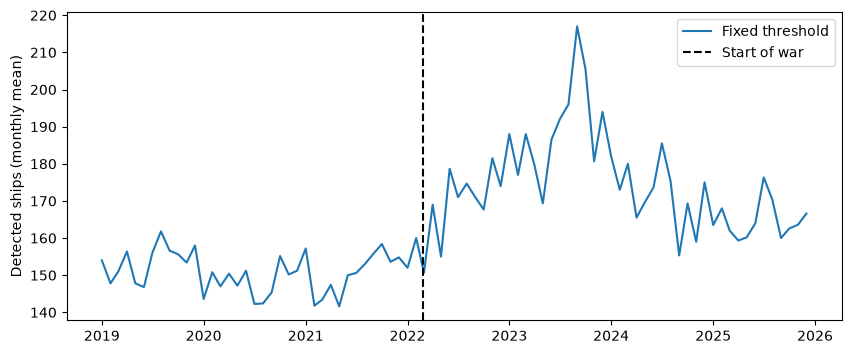

         before war  after war
n_ships       151.0      172.9


In [33]:
# Monthly average, so the plot is less noisy than 322 single dates
monthly = counts.resample('MS').mean()
war_start = '2022-02-24'

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly['n_ships'], label='Fixed threshold')

ax.axvline(pd.Timestamp(war_start), color='black', linestyle='--', label='Start of war')
ax.set_ylabel('Detected ships (monthly mean)')
ax.legend()
fig.savefig(os.path.join(output_dir, 'ship_counts.png'), dpi=150, bbox_inches='tight')
plt.show()

# Average number of ships per image, before and after the start of the war
before = counts[counts.index < war_start].mean()
after = counts[counts.index >= war_start].mean()
print(pd.DataFrame({'before war': before, 'after war': after}).round(1))

counts.to_csv(os.path.join(data_dir, 'ship_counts.csv'))